In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import xgboost as xgb

In [2]:
data = pd.read_csv('/content/credit_risk_dataset.csv')

In [3]:
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [5]:
data['person_age'].max()

144

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
data.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [8]:
data.describe(include='object')

,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


EXPLORATORY DATA ANALYSIS


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [10]:
data.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [11]:
data['person_emp_length'].dtype

dtype('float64')

In [12]:
data['person_emp_length'].value_counts()

,count
person_emp_length,
0.0,4105
2.0,3849
3.0,3456
5.0,2946
1.0,2915
4.0,2874
6.0,2666
7.0,2196
8.0,1687


In [13]:
data['person_emp_length'].unique()

array([123.,   5.,   1.,   4.,   8.,   2.,   6.,   7.,   0.,   9.,   3.,
        10.,  nan,  11.,  18.,  12.,  17.,  14.,  16.,  13.,  19.,  15.,
        20.,  22.,  21.,  24.,  23.,  26.,  25.,  27.,  28.,  31.,  41.,
        34.,  29.,  38.,  30.])

In [14]:
len(data[data['person_emp_length'].isna()==True])/len(data['person_emp_length'])

0.027469997851508547

In [15]:
data['person_emp_length'].fillna(data['person_emp_length'].median(), inplace=True)

/tmp/ipykernel_4905/3990055313.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['person_emp_length'].fillna(data['person_emp_length'].median(), inplace=True)


In [16]:
data['person_emp_length'].isna()

,person_emp_length
0,False
1,False
2,False
3,False
4,False
...,...
32576,False
32577,False
32578,False
32579,False


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [18]:
data['loan_int_rate'].value_counts()

,count
loan_int_rate,
7.51,756
10.99,749
7.49,645
7.88,642
5.42,594
...,...
23.22,1
16.71,1
18.54,1


In [19]:
interest_count=data['loan_int_rate'].value_counts()
interest_count

,count
loan_int_rate,
7.51,756
10.99,749
7.49,645
7.88,642
5.42,594
...,...
23.22,1
16.71,1
18.54,1


In [20]:
interest_count[interest_count < 5]

,count
loan_int_rate,
19.79,4
15.25,4
21.21,4
18.99,4
20.25,4
...,...
23.22,1
16.71,1
18.54,1


In [21]:
len(data[data['loan_int_rate'].isna()])

3116

In [22]:
data['loan_int_rate'].unique()

array([16.02, 11.14, 12.87, 15.23, 14.27,  7.14, 12.42, 11.11,  8.9 ,
       14.74, 10.37,  8.63,  7.9 , 18.39, 10.65, 20.25, 18.25, 10.99,
        7.49, 16.77, 17.58,  7.29, 14.54, 12.68, 17.74,  9.32,  9.99,
       12.84, 11.12,  6.62, 14.17, 13.85, 13.49,  7.51, 16.89,   nan,
       17.99, 12.69,  7.88, 19.41, 10.38, 15.33, 16.45, 18.62, 15.96,
       11.48,  5.99, 11.58, 15.7 , 15.99, 14.84, 14.42,  6.99, 13.61,
        9.91, 13.48, 12.98, 13.57, 15.68, 13.06, 15.62, 11.71,  8.88,
       12.18, 13.99,  5.42, 12.73, 11.49, 19.91, 11.83, 14.59,  9.64,
       16.35, 18.67, 10.08, 10.36, 12.23, 16.07, 14.22, 14.79, 13.22,
       11.86, 13.43, 15.28, 17.93,  9.25, 10.62, 18.43, 11.36, 15.65,
       13.04, 17.04, 14.83, 14.65, 16.82, 10.25, 14.96, 11.99,  8.49,
        6.17, 16.32, 14.35, 15.21, 14.09, 17.49, 13.92, 16.49,  5.79,
       13.11,  6.54, 12.53, 15.95, 10.74, 15.27, 14.72, 13.35,  7.68,
       14.46, 13.47,  6.03, 12.92, 18.64, 16.7 , 18.3 ,  9.63, 14.7 ,
       15.37, 14.26,

In [23]:
if (data['loan_int_rate'] == 0.0).any():
  print("yes")
  print(data[data['loan_int_rate'] == 0.0])
else:
  print('no')

no


In [24]:
data['loan_int_rate'].replace({np.nan: 1}, inplace=True)

/tmp/ipykernel_4905/3385698060.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['loan_int_rate'].replace({np.nan: 1}, inplace=True)


In [25]:
data.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [26]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.767994,9589.371106,10.054191,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.087372,6322.086646,4.262156,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,1.000000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.620000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [27]:
import seaborn as sns

<Axes: xlabel='person_age', ylabel='Count'>

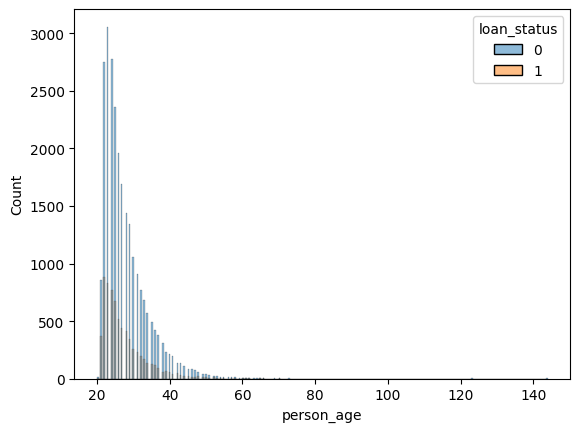

In [28]:
sns.histplot(data=data, x='person_age', hue='loan_status')

<Axes: xlabel='person_home_ownership', ylabel='count'>

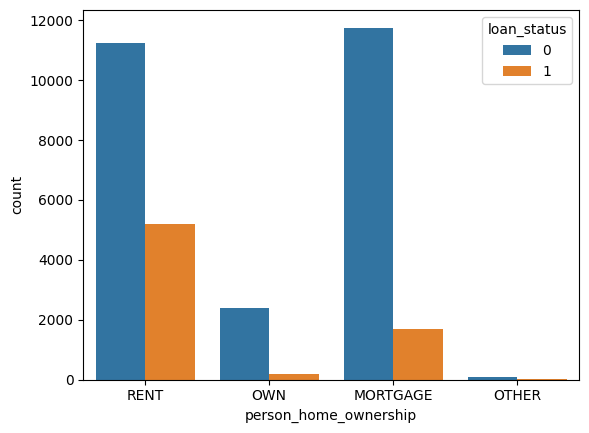

In [29]:
sns.countplot(data=data, x='person_home_ownership', hue='loan_status')

<Axes: >

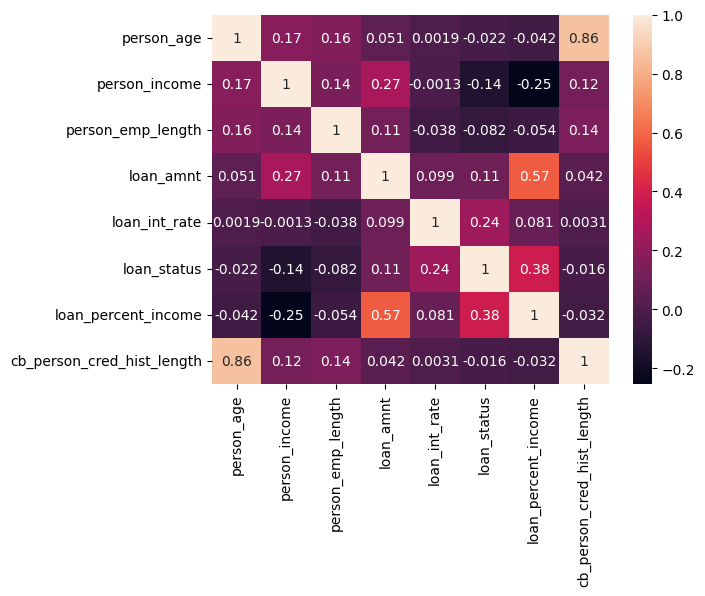

In [30]:
sns.heatmap(data.corr(numeric_only=True), annot=True)

In [31]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [32]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.767994,9589.371106,10.054191,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.087372,6322.086646,4.262156,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,1.000000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.620000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [33]:
data.rename(columns={'years':'months_of_employment'}, inplace=True)

In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [35]:
data['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


In [36]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.767994,9589.371106,10.054191,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.087372,6322.086646,4.262156,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,1.000000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.620000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [37]:
from functools import update_wrapper
# i want to clip the person_emp_length column
lower_cap=data['person_emp_length'].quantile(0.10)
upper_cap=data['person_emp_length'].quantile(0.95)
data['person_emp_length']=data['person_emp_length'].clip(lower_cap, upper_cap)

In [38]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.583101,9589.371106,10.054191,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,3.484783,6322.086646,4.262156,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,1.000000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.620000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,12.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [39]:
# i also want to clip the age column
lower_cap=data['person_age'].quantile(0.10)
upper_cap=data['person_age'].quantile(0.95)
data['person_age']=data['person_age'].clip(lower_cap, upper_cap)

In [40]:
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,12.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,22,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [41]:
data.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [42]:
#i need to rename some columns
data.rename(columns={'person_emp_length':'employment_length'}, inplace=True)
data.rename(columns={'person_income':'annual_income'}, inplace=True)
data.rename(columns={'person_home_ownership':'home_ownership'}, inplace=True)
data.rename(columns={'person_emp_title':'employment_title'}, inplace=True)
data.rename(columns={'loan_intent':'loan_purpose'}, inplace=True)
data.rename(columns={'loan_amnt':'loan_amount'}, inplace=True)
data.rename(columns={'loan_int_rate':'interest_rate'}, inplace=True)
data.rename(columns={'cb_person_default_on_file':'default_record'}, inplace=True)

In [43]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   annual_income               32581 non-null  int64  
 2   home_ownership              32581 non-null  object 
 3   employment_length           32581 non-null  float64
 4   loan_purpose                32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amount                 32581 non-null  int64  
 7   interest_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  default_record              32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [44]:
data.rename(columns={'employment_length':'months_in_employment'}, inplace=True)

In [45]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   annual_income               32581 non-null  int64  
 2   home_ownership              32581 non-null  object 
 3   months_in_employment        32581 non-null  float64
 4   loan_purpose                32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amount                 32581 non-null  int64  
 7   interest_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  default_record              32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [46]:
data.rename(columns={'cb_person_cred_hist_length':'credit_history_years'}, inplace=True)
data.rename(columns={'person_age':'age'}, inplace=True)


In [47]:
data['loan_grade'].value_counts()

,count
loan_grade,
A,10777
B,10451
C,6458
D,3626
E,964
F,241
G,64


In [48]:
grade_mapping={
    'A':1,
    'B':2,
    'C':3,
    'D':4,
    'E':5,
    'F':6,
    'G':7
}
data['loan_grade']=data['loan_grade'].map(grade_mapping)

In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   32581 non-null  int64  
 1   annual_income         32581 non-null  int64  
 2   home_ownership        32581 non-null  object 
 3   months_in_employment  32581 non-null  float64
 4   loan_purpose          32581 non-null  object 
 5   loan_grade            32581 non-null  int64  
 6   loan_amount           32581 non-null  int64  
 7   interest_rate         32581 non-null  float64
 8   loan_status           32581 non-null  int64  
 9   loan_percent_income   32581 non-null  float64
 10  default_record        32581 non-null  object 
 11  credit_history_years  32581 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 3.0+ MB


In [50]:
data['loan_status'].value_counts(normalize=True)

,proportion
loan_status,
0,0.781836
1,0.218164


In [51]:
data['loan_percent_income']

,loan_percent_income
0,0.59
1,0.10
2,0.57
3,0.53
4,0.55
...,...
32576,0.11
32577,0.15
32578,0.46
32579,0.10


In [52]:
data.rename(columns={'loan_percent_income':'loan_to_income_ratio'}, inplace=True)

In [53]:
data['interest_rate']

,interest_rate
0,16.02
1,11.14
2,12.87
3,15.23
4,14.27
...,...
32576,13.16
32577,7.49
32578,10.99
32579,11.48


In [54]:
data['gross_loan_amount']=data['loan_amount']*(data['interest_rate']/100)

In [55]:
data.drop(columns={'loan_amount'}, inplace=True)

In [56]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   32581 non-null  int64  
 1   annual_income         32581 non-null  int64  
 2   home_ownership        32581 non-null  object 
 3   months_in_employment  32581 non-null  float64
 4   loan_purpose          32581 non-null  object 
 5   loan_grade            32581 non-null  int64  
 6   interest_rate         32581 non-null  float64
 7   loan_status           32581 non-null  int64  
 8   loan_to_income_ratio  32581 non-null  float64
 9   default_record        32581 non-null  object 
 10  credit_history_years  32581 non-null  int64  
 11  gross_loan_amount     32581 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 3.0+ MB


In [57]:
data['default_record']

,default_record
0,Y
1,N
2,N
3,N
4,Y
...,...
32576,N
32577,N
32578,N
32579,N


In [58]:
data['loan_purpose'].value_counts()

,count
loan_purpose,
EDUCATION,6453
MEDICAL,6071
VENTURE,5719
PERSONAL,5521
DEBTCONSOLIDATION,5212
HOMEIMPROVEMENT,3605


<Axes: xlabel='loan_purpose', ylabel='count'>

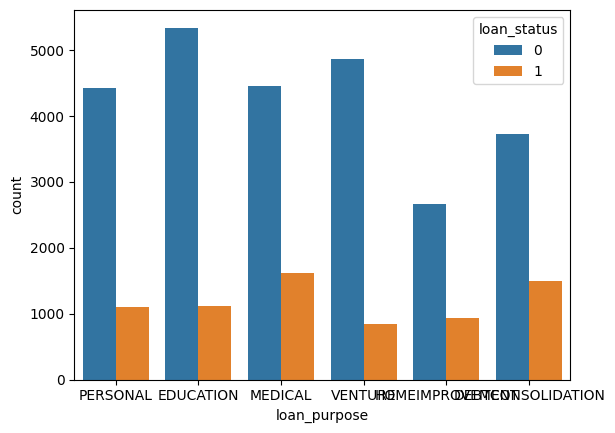

In [59]:
sns.countplot(data=data, x='loan_purpose', hue='loan_status')

In [60]:
data.nunique()

,0
age,19
annual_income,4295
home_ownership,4
months_in_employment,13
loan_purpose,6
loan_grade,7
interest_rate,349
loan_status,2
loan_to_income_ratio,77
default_record,2


In [61]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   32581 non-null  int64  
 1   annual_income         32581 non-null  int64  
 2   home_ownership        32581 non-null  object 
 3   months_in_employment  32581 non-null  float64
 4   loan_purpose          32581 non-null  object 
 5   loan_grade            32581 non-null  int64  
 6   interest_rate         32581 non-null  float64
 7   loan_status           32581 non-null  int64  
 8   loan_to_income_ratio  32581 non-null  float64
 9   default_record        32581 non-null  object 
 10  credit_history_years  32581 non-null  int64  
 11  gross_loan_amount     32581 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 3.0+ MB


In [62]:
numerical_columns=['age','annual_income','months_in_employment','credit_history_years','loan_to_income_ratio','gross_loan_amount']
categorical_columns=['loan_grade','home_ownership','employment_title','loan_purpose']

In [63]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ])

In [64]:
#train test split
X=data.drop(columns=['loan_status'])
y=data['loan_status']
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,stratify=y, random_state=42)

In [65]:
from sklearn.preprocessing import StandardScaler

In [66]:
# Redefine categorical columns to only include those present in the dataset
categorical_columns = ['loan_grade', 'home_ownership', 'loan_purpose']

# Re-initialize the preprocessor without 'employment_title'
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ])

# Build and fit the baseline model
baseline = LogisticRegression(max_iter=1000, class_weight='balanced')
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', baseline)
])

baseline_pipeline.fit(X_train, y_train)
y_pred = baseline_pipeline.predict(X_test)
score = roc_auc_score(y_test, y_pred)
print(f'roc_auc_score:{score}')
baseline_accuracy = baseline_pipeline.score(X_test, y_test)
print("Baseline Accuracy:", baseline_accuracy)


roc_auc_score:0.7985633718835792
Baseline Accuracy: 0.8098818474758325


In [67]:
from sklearn.ensemble import RandomForestClassifier

In [68]:
rf_pipeline=Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

In [69]:
# i want to try and build more robust model
from sklearn.model_selection import RandomizedSearchCV

# Prefix the parameters with the step name 'classifier__' so the Pipeline can route them correctly
param_dist = {
    'classifier__n_estimators': [100, 200, 300, 400, 500],
    'classifier__max_depth': [None, 5, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2', None]
}

random_search = RandomizedSearchCV(rf_pipeline, param_distributions=param_dist, n_iter=10, cv=5, scoring='roc_auc', n_jobs=-1, verbose=2, random_state=42)
random_search.fit(X_train, y_train)
best_params = random_search.best_params_
print(f'Best Parameters: {best_params}')
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)
score = roc_auc_score(y_test, y_pred)
print(f'roc_auc_score:{score}')

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__n_estimators': 400, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 20}
roc_auc_score:0.8636451030974079


In [70]:
scale_pos_weight=(y_train==0).sum()/(y_train==1).sum()
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(random_state=42, scale_pos_weight=scale_pos_weight))
])
param_dist={
    'classifier__n_estimators': [100, 200, 300, 400, 500],
    'classifier__max_depth': [3, 4, 5, 6, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2, 0.3, 0.4],
    'classifier__subsample': [0.8, 0.9, 1.0]
}
rand_search=RandomizedSearchCV(xgb_pipeline, param_distributions=param_dist, n_iter=10, cv=5, scoring='roc_auc', n_jobs=-1, verbose=2, random_state=42)
rand_search.fit(X_train, y_train)
best_params=rand_search.best_params_
print(f'Best Parameters: {best_params}')
best_model_x=rand_search.best_estimator_
y_pred=best_model.predict(X_test)
score=roc_auc_score(y_test, y_pred)
print(f'roc_auc_score:{score}')


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__subsample': 1.0, 'classifier__n_estimators': 500, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1}
roc_auc_score:0.8636451030974079


In [71]:
# Access the XGBoost classifier from the pipeline step to get feature importances
importances = best_model_x.named_steps['classifier'].feature_importances_

# To make it readable, let's map importances to their feature names
# 1. Get feature names from the preprocessor step
feature_names = (
    numerical_columns +
    list(best_model_x.named_steps['preprocessor']
         .named_transformers_['cat']
         .get_feature_names_out(categorical_columns))
)

# Create a DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

importance_df

,Feature,Importance
9,loan_grade_4,0.194898
10,loan_grade_5,0.098363
15,home_ownership_OWN,0.092664
16,home_ownership_RENT,0.091691
6,loan_grade_1,0.068312
4,loan_to_income_ratio,0.056770
22,loan_purpose_VENTURE,0.046552
11,loan_grade_6,0.045852
7,loan_grade_2,0.042912
19,loan_purpose_HOMEIMPROVEMENT,0.037997


In [72]:
from sklearn.metrics import classification_report, confusion_matrix

In [73]:
cm=confusion_matrix(y_test, y_pred)
cr=classification_report(y_test, y_pred)
print(f'confusion matrix: {cm}')
print(f'classification report: {cr}')

confusion matrix: [[4999   96]
 [ 361 1061]]
classification report:               precision    recall  f1-score   support

           0       0.93      0.98      0.96      5095
           1       0.92      0.75      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.92      0.86      0.89      6517
weighted avg       0.93      0.93      0.93      6517



In [74]:
import joblib

In [75]:
pipeline=Pipeline([
    ('preprocessor', preprocessor),
    ('pipe', xgb_pipeline),
    ('classifier_x', best_model_x)
])
joblib.dump(pipeline, 'loan_pipeline_xgb.pkl')
rf_pipe=Pipeline([
    ('preprocessor', preprocessor),
    ('pipe', rf_pipeline),
    ('classifier', best_model)
])
joblib.dump(rf_pipe, 'loan_pipeline_rf.pkl')

['loan_pipeline_rf.pkl']

In [76]:
# Save the correct, pre-existing pipelines directly without nesting them
joblib.dump(best_model_x, 'loan_pipeline_xgb.pkl')
joblib.dump(best_model, 'loan_pipeline_rf.pkl')

# Load and test the corrected model pipeline
loaded_model = joblib.load('loan_pipeline_xgb.pkl')
loaded_model.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(6517,))